# CA1 
The dataset selected was the "Indian Liver Patient Dataset (ILPD)"; this is a medical dataset containing biochemical markers and other patient parameters, intended to facilitate the early detection of liver diseases (Ramana and Venkateswarlu, 2022).

The question this project will address is: 

is it possible to accurately predict whether a patient has liver disease based on sociodemographic parameters (age and sex) and blood parameters (bilirubin, alkaline phosphatase, to name a few)? Which models are most optimal for this dataset, and which parameters are the most important?

In [1]:
#Import libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

### CHARACTERIZATION OF DATA

In [2]:
df= pd.read_csv("ILPD.csv")

In [3]:
df

,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.9,1
0,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
1,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
2,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
3,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1
4,46,Male,1.8,0.7,208,19,14,7.6,4.4,1.30,1
...,...,...,...,...,...,...,...,...,...,...,...
577,60,Male,0.5,0.1,500,20,34,5.9,1.6,0.37,2
578,40,Male,0.6,0.1,98,35,31,6.0,3.2,1.10,1
579,52,Male,0.8,0.2,245,48,49,6.4,3.2,1.00,1
580,31,Male,1.3,0.5,184,29,32,6.8,3.4,1.00,1


In [4]:
data= pd.read_csv("ILPD.csv", header=None)

data.columns = ["Age", "Gender", "Total Bilirubin", "Direct Bilirubin", "Alkaline Phosphotase",
    "Alamine Aminotransferase", "Aspartate Aminotransferase", "Total Proteins", "Albumin", 
"Albumin and Globulin Ratio", "Target"]

In [5]:
data


,Age,Gender,Total Bilirubin,Direct Bilirubin,Alkaline Phosphotase,Alamine Aminotransferase,Aspartate Aminotransferase,Total Proteins,Albumin,Albumin and Globulin Ratio,Target
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1
...,...,...,...,...,...,...,...,...,...,...,...
578,60,Male,0.5,0.1,500,20,34,5.9,1.6,0.37,2
579,40,Male,0.6,0.1,98,35,31,6.0,3.2,1.10,1
580,52,Male,0.8,0.2,245,48,49,6.4,3.2,1.00,1
581,31,Male,1.3,0.5,184,29,32,6.8,3.4,1.00,1


In [6]:
data.shape

(583, 11)

In [7]:
data.describe()

,Age,Total Bilirubin,Direct Bilirubin,Alkaline Phosphotase,Alamine Aminotransferase,Aspartate Aminotransferase,Total Proteins,Albumin,Albumin and Globulin Ratio,Target
count,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,579.000000,583.000000
mean,44.746141,3.298799,1.486106,290.576329,80.713551,109.910806,6.483190,3.141852,0.947064,1.286449
std,16.189833,6.209522,2.808498,242.937989,182.620356,288.918529,1.085451,0.795519,0.319592,0.452490
min,4.000000,0.400000,0.100000,63.000000,10.000000,10.000000,2.700000,0.900000,0.300000,1.000000
25%,33.000000,0.800000,0.200000,175.500000,23.000000,25.000000,5.800000,2.600000,0.700000,1.000000
50%,45.000000,1.000000,0.300000,208.000000,35.000000,42.000000,6.600000,3.100000,0.930000,1.000000
75%,58.000000,2.600000,1.300000,298.000000,60.500000,87.000000,7.200000,3.800000,1.100000,2.000000
max,90.000000,75.000000,19.700000,2110.000000,2000.000000,4929.000000,9.600000,5.500000,2.800000,2.000000


In [8]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 583 entries, 0 to 582
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         583 non-null    int64  
 1   Gender                      583 non-null    str    
 2   Total Bilirubin             583 non-null    float64
 3   Direct Bilirubin            583 non-null    float64
 4   Alkaline Phosphotase        583 non-null    int64  
 5   Alamine Aminotransferase    583 non-null    int64  
 6   Aspartate Aminotransferase  583 non-null    int64  
 7   Total Proteins              583 non-null    float64
 8   Albumin                     583 non-null    float64
 9   Albumin and Globulin Ratio  579 non-null    float64
 10  Target                      583 non-null    int64  
dtypes: float64(5), int64(5), str(1)
memory usage: 52.8 KB


In [9]:
data.isnull().sum()

Age                           0
Gender                        0
Total Bilirubin               0
Direct Bilirubin              0
Alkaline Phosphotase          0
Alamine Aminotransferase      0
Aspartate Aminotransferase    0
Total Proteins                0
Albumin                       0
Albumin and Globulin Ratio    4
Target                        0
dtype: int64

In [10]:
data["Albumin and Globulin Ratio"].unique()

array([0.9 , 0.74, 0.89, 1.  , 0.4 , 1.3 , 1.1 , 1.2 , 0.8 , 0.6 , 0.87,
       0.7 , 0.92, 0.55, 0.5 , 1.85, 0.95, 1.4 , 1.18, 0.61, 1.34, 1.39,
       1.6 , 1.58, 1.25, 0.78, 0.76, 1.55, 0.71, 0.62, 0.67, 0.75, 1.16,
       1.5 , 1.66, 0.96, 1.38, 0.52, 0.47, 0.93, 0.48, 0.58, 0.69, 1.27,
       1.12, 1.06, 0.53, 1.03, 0.68,  nan, 1.9 , 1.7 , 1.8 , 0.3 , 0.97,
       0.35, 1.51, 0.64, 0.45, 1.36, 0.88, 1.09, 1.11, 1.72, 2.8 , 0.46,
       0.39, 1.02, 2.5 , 0.37])

In [11]:
data["Albumin and Globulin Ratio"]= data["Albumin and Globulin Ratio"].fillna(data["Albumin and Globulin Ratio"].median())

In [12]:
data.isnull().sum()

Age                           0
Gender                        0
Total Bilirubin               0
Direct Bilirubin              0
Alkaline Phosphotase          0
Alamine Aminotransferase      0
Aspartate Aminotransferase    0
Total Proteins                0
Albumin                       0
Albumin and Globulin Ratio    0
Target                        0
dtype: int64

In [13]:
data["Albumin and Globulin Ratio"].unique()

array([0.9 , 0.74, 0.89, 1.  , 0.4 , 1.3 , 1.1 , 1.2 , 0.8 , 0.6 , 0.87,
       0.7 , 0.92, 0.55, 0.5 , 1.85, 0.95, 1.4 , 1.18, 0.61, 1.34, 1.39,
       1.6 , 1.58, 1.25, 0.78, 0.76, 1.55, 0.71, 0.62, 0.67, 0.75, 1.16,
       1.5 , 1.66, 0.96, 1.38, 0.52, 0.47, 0.93, 0.48, 0.58, 0.69, 1.27,
       1.12, 1.06, 0.53, 1.03, 0.68, 1.9 , 1.7 , 1.8 , 0.3 , 0.97, 0.35,
       1.51, 0.64, 0.45, 1.36, 0.88, 1.09, 1.11, 1.72, 2.8 , 0.46, 0.39,
       1.02, 2.5 , 0.37])

In [14]:
data["Gender"].unique()

<ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str

In [15]:
data["Target"]=data["Target"].replace({2:0})

In [16]:
data["Target"].unique()

array([1, 0])

In [17]:
data

,Age,Gender,Total Bilirubin,Direct Bilirubin,Alkaline Phosphotase,Alamine Aminotransferase,Aspartate Aminotransferase,Total Proteins,Albumin,Albumin and Globulin Ratio,Target
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1
...,...,...,...,...,...,...,...,...,...,...,...
578,60,Male,0.5,0.1,500,20,34,5.9,1.6,0.37,0
579,40,Male,0.6,0.1,98,35,31,6.0,3.2,1.10,1
580,52,Male,0.8,0.2,245,48,49,6.4,3.2,1.00,1
581,31,Male,1.3,0.5,184,29,32,6.8,3.4,1.00,1


In [18]:
data["Gender"]=data["Gender"].map({'Male': 1, 'Female':0})

In [19]:
data.head()

,Age,Gender,Total Bilirubin,Direct Bilirubin,Alkaline Phosphotase,Alamine Aminotransferase,Aspartate Aminotransferase,Total Proteins,Albumin,Albumin and Globulin Ratio,Target
0,65,0,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,1,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,1,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,1,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,1,3.9,2.0,195,27,59,7.3,2.4,0.40,1


In [20]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 583 entries, 0 to 582
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         583 non-null    int64  
 1   Gender                      583 non-null    int64  
 2   Total Bilirubin             583 non-null    float64
 3   Direct Bilirubin            583 non-null    float64
 4   Alkaline Phosphotase        583 non-null    int64  
 5   Alamine Aminotransferase    583 non-null    int64  
 6   Aspartate Aminotransferase  583 non-null    int64  
 7   Total Proteins              583 non-null    float64
 8   Albumin                     583 non-null    float64
 9   Albumin and Globulin Ratio  583 non-null    float64
 10  Target                      583 non-null    int64  
dtypes: float64(5), int64(6)
memory usage: 50.2 KB


### Modeling and cross validation

In [21]:
from matplotlib import pyplot
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn import metrics
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import RobustScaler

In [22]:
#Define features (X) and target variable (Y)
X= data.drop(columns=["Target"]) 
y=data["Target"]

#Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.05, random_state = 42)

In [23]:
#standardizing the data
scaler=MinMaxScaler()
X_train_scaled= scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)


In [24]:
classifiers = {
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Support Vector Machine": SVC(kernel='linear', random_state=42)
}

In [25]:
results=[]
for name, classifier in classifiers.items():
    classifier.fit(X_train_scaled, y_train)

    y_pred=classifier.predict(X_test_scaled)

    accuracy= accuracy_score(y_test, y_pred)
    report= classification_report(y_test, y_pred, output_dict=True, zero_division=0)
    precision= report['weighted avg']['precision']
    recall= report['weighted avg']['recall']
    f1_score= report['weighted avg']['f1-score']

    results.append([name, accuracy, precision, recall, f1_score])

In [26]:
results_data=pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_data)

Model Performance Metrics on Test Set:
                    Model  Accuracy  Precision    Recall  F1 Score
0           Random Forest  0.933333   0.938889  0.933333  0.930021
1     Logistic Regression  0.733333   0.537778  0.733333  0.620513
2  Support Vector Machine  0.733333   0.537778  0.733333  0.620513


In [27]:
#Applying cross validation
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline

skf= StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

cv_classifiers = {
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "LogisticRegression": make_pipeline(MinMaxScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    "Support Vector Machine": make_pipeline(MinMaxScaler(), SVC(kernel='linear', random_state=42))}

cv_results=[]

for name, classifier in cv_classifiers.items():
    cv_scores=cross_val_score(classifier, X_train, y_train, cv=skf, scoring='accuracy')

    cv_results.append([name, cv_scores.mean()])
    cv_results_data=pd.DataFrame(cv_results, columns=["Model", "Mean CV Accuracy"])
    
print ("\nCross-Validation Accuracy Scores:")
print(cv_results_data)


Cross-Validation Accuracy Scores:
                    Model  Mean CV Accuracy
0           Random Forest          0.672727
1      LogisticRegression          0.703423
2  Support Vector Machine          0.712482


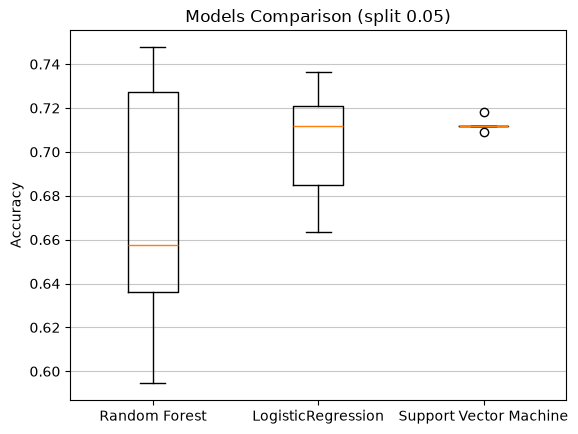

In [28]:
all_scores=[]
model_names=[]

for name, classifier in cv_classifiers.items():
    cv_scores=cross_val_score(classifier, X_train, y_train, cv=skf, scoring='accuracy', n_jobs=1)
    all_scores.append(cv_scores)
    model_names.append(name)

plt.boxplot(all_scores)
plt.ylabel('Accuracy')
plt.title('Models Comparison (split 0.05)')
plt.xticks(ticks=[1,2,3], labels=model_names )
plt.grid(axis='y',  alpha=0.7)
plt.show()

### Apply SMOTE to balance the training dataset

In [29]:
#Show count of each class in the target variable
class_counts= y.value_counts()
print("Count of each class in Target variable")
print(class_counts)

Count of each class in Target variable
Target
1    416
0    167
Name: count, dtype: int64


In [30]:
y=data["Target"]

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

scaler=MinMaxScaler()
X2_train_scaled=scaler.fit_transform(X_train)
X2_test_scaled=scaler.transform(X_test)

In [32]:
from imblearn.over_sampling import SMOTE

# Apply SMOTE to balance the classes in the training set

smote=SMOTE(random_state=42)
XS_train, ys_train= smote.fit_resample(X2_train_scaled, y_train)

In [33]:
# Show count of each class in the target variable
class_counts=ys_train.value_counts()
print("Count of each class in 'Target' variable")
print(class_counts)


Count of each class in 'Target' variable
Target
1    307
0    307
Name: count, dtype: int64


In [34]:
# Train and evaluate classifiers

results=[]
for name, classifier in classifiers.items():
    classifier.fit(XS_train, ys_train)

    y_pred=classifier.predict(X2_test_scaled)

    accuracy= accuracy_score(y_test, y_pred)
    report=classification_report(y_test, y_pred, output_dict=True, zero_division=0)
    precision=report['weighted avg']['precision']
    recall=report['weighted avg']['recall']
    f1_score=report['weighted avg']['f1-score']

    results.append([name, accuracy, precision, recall, f1_score])

In [35]:
# Convert results to DataFrame for easy viewing
results_data = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_data)

Model Performance Metrics on Test Set:
                    Model  Accuracy  Precision    Recall  F1 Score
0           Random Forest  0.664384   0.685023  0.664384  0.673318
1     Logistic Regression  0.684932   0.826017  0.684932  0.704806
2  Support Vector Machine  0.568493   0.809107  0.568493  0.584144


### GridSearchCV for all models

In [43]:
from sklearn.model_selection import GridSearchCV


In [44]:
classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Support Vector Machine": SVC(kernel='linear', random_state=42),
}

In [45]:
param_grids = {
    "Logistic Regression": {
        "C": [0.1, 1, 10],
        "solver": ['lbfgs', 'liblinear']
    },
      "Random Forest": {
        "n_estimators": [50, 100, 200],
        "max_depth": [None, 10, 20, 30]
    },
     "Support Vector Machine": {
        "C": [0.1, 1, 10],
        "kernel": ['linear', 'rbf']
    }
}

In [46]:
# Apply GridSearchCV for each classifier and evaluate performance metric scores
results = []
for name, classifier in classifiers.items():
    print(f"Running GridSearchCV for {name}...")
    grid_search = GridSearchCV(estimator=classifier, param_grid=param_grids[name], cv = 5, n_jobs = -1, verbose = 2)
    grid_search.fit(XS_train, ys_train)
    
    # Best model from grid search
    best_model = grid_search.best_estimator_
    
    # Predict on the test set with the best model
    y_pred = best_model.predict(X2_test_scaled)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score, grid_search.best_params_])

Running GridSearchCV for Logistic Regression...
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Running GridSearchCV for Random Forest...
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Running GridSearchCV for Support Vector Machine...
Fitting 5 folds for each of 6 candidates, totalling 30 fits


In [47]:
# Convert results to DataFrame for easy viewing
results_data2 = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score", "Best Parameters"])
print("Model Performance Metrics on Test Set after GridSearchCV:")
print(results_data2)

Model Performance Metrics on Test Set after GridSearchCV:
                    Model  Accuracy  Precision    Recall  F1 Score  \
0     Logistic Regression  0.650685   0.828086  0.650685  0.670522   
1           Random Forest  0.650685   0.677942  0.650685  0.662103   
2  Support Vector Machine  0.609589   0.818466  0.609589  0.628350   

                          Best Parameters  
0            {'C': 10, 'solver': 'lbfgs'}  
1  {'max_depth': 20, 'n_estimators': 100}  
2              {'C': 10, 'kernel': 'rbf'}  


In [48]:
# Cross-validation for accuracy on the full dataset using best models
cv_results = []
for name, classifier in classifiers.items():
    # Get the best model from GridSearchCV
    grid_search = GridSearchCV(estimator=classifier, param_grid=param_grids[name], cv=5, n_jobs=-1, verbose=2)
    grid_search.fit(XS_train, ys_train)
    best_model = grid_search.best_estimator_
    
    cv_scores = cross_val_score(best_model, XS_train, ys_train, cv=5, scoring='accuracy')
    cv_results.append([name, cv_scores.mean()])

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Fitting 5 folds for each of 6 candidates, totalling 30 fits


In [49]:
# Display cross-validation results
cv_results_data = pd.DataFrame(cv_results, columns=["Model", "Mean CV Accuracy"])
print("\nCross-Validation Accuracy Scores after GridSearchCV:")
print(cv_results_data)


Cross-Validation Accuracy Scores after GridSearchCV:
                    Model  Mean CV Accuracy
0     Logistic Regression          0.710223
1           Random Forest          0.781861
2  Support Vector Machine          0.716700


### REFERENCES